In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from scipy import stats
from scipy.stats import norm

from pathlib import Path

In [41]:
df = pd.read_csv("dados/dados_SIM_Para_Analise.csv")
df.shape
df['DTOBITO'] = pd.to_datetime(df['DTOBITO'], errors='coerce')

In [42]:
df.columns

Index(['CAUSABAS', 'DTOBITO', 'SEXO', 'IDADE', 'TIPOBITO', 'RACACOR',
       'ESC2010', 'ESCFALAGR1', 'LOCOCOR', 'ASSISTMED', 'codUf', 'ANOOBITO',
       'Capital', 'Sigla UF'],
      dtype='object')

In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17780 entries, 0 to 17779
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   CAUSABAS    17780 non-null  object        
 1   DTOBITO     17780 non-null  datetime64[ns]
 2   SEXO        17780 non-null  int64         
 3   IDADE       17780 non-null  int64         
 4   TIPOBITO    17780 non-null  int64         
 5   RACACOR     17780 non-null  float64       
 6   ESC2010     17780 non-null  float64       
 7   ESCFALAGR1  17780 non-null  float64       
 8   LOCOCOR     17780 non-null  int64         
 9   ASSISTMED   17780 non-null  float64       
 10  codUf       17780 non-null  int64         
 11  ANOOBITO    17780 non-null  int64         
 12  Capital     17780 non-null  object        
 13  Sigla UF    17780 non-null  object        
dtypes: datetime64[ns](1), float64(4), int64(6), object(3)
memory usage: 1.9+ MB


In [44]:
'CAUSABAS', 
'DTOBITO', 
'SEXO',
'IDADE',
'TIPOBITO',
'RACACOR',
'ESC2010',
'ESCFALAGR1',
'LOCOCOR',
'ASSISTMED',
'codUf',
'ANOOBITO',
'Capital',
'Sigla UF'

'Sigla UF'

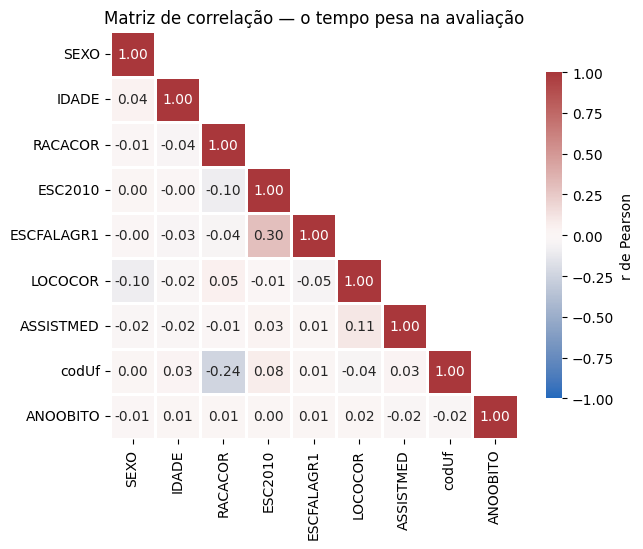

In [81]:
num = [ 
'SEXO',
'IDADE',
'RACACOR',
'ESC2010',
'ESCFALAGR1',
'LOCOCOR',
'ASSISTMED',
'codUf',
'ANOOBITO',

]
rotulos = [ 
'SEXO',
'IDADE',
'RACACOR',
'ESC2010',
'ESCFALAGR1',
'LOCOCOR',
'ASSISTMED',
'codUf',
'ANOOBITO',
]
corr = df[num].corr(method="pearson")
corr.index = corr.columns = rotulos
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7, 5.6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0,
            square=True, linewidths=1, linecolor="white",
            cbar_kws=dict(label="r de Pearson", shrink=0.8), annot_kws=dict(size=10), ax=ax)
ax.grid(False)
ax.set_title("Matriz de correlação — o tempo pesa na avaliação")
fig.tight_layout()
fig.savefig("fig/heatmap_correlacao.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
df

In [ ]:
#df_natal = df.loc[df['Capital'] == 'Natal']
#df_natal.groupby(['ANOOBITO'])['CAUSABAS'].count().reset_index()

,ANOOBITO,CAUSABAS
0,2022,135
1,2023,101
2,2024,107
3,2025,50


In [ ]:
#df_natal['MESOBITO'] = df_natal['DTOBITO'].dt.month
#dftx = df.loc[(df['IDADE'] <= 35)  & (df['ANOOBITO'] <=2024)]
dft = df.groupby(['IDADE'])['CAUSABAS'].count().reset_index()
print(dft.shape)


dft.head()




(27, 2)


,IDADE,CAUSABAS
0,18,68
1,19,80
2,20,95
3,21,127
4,22,132


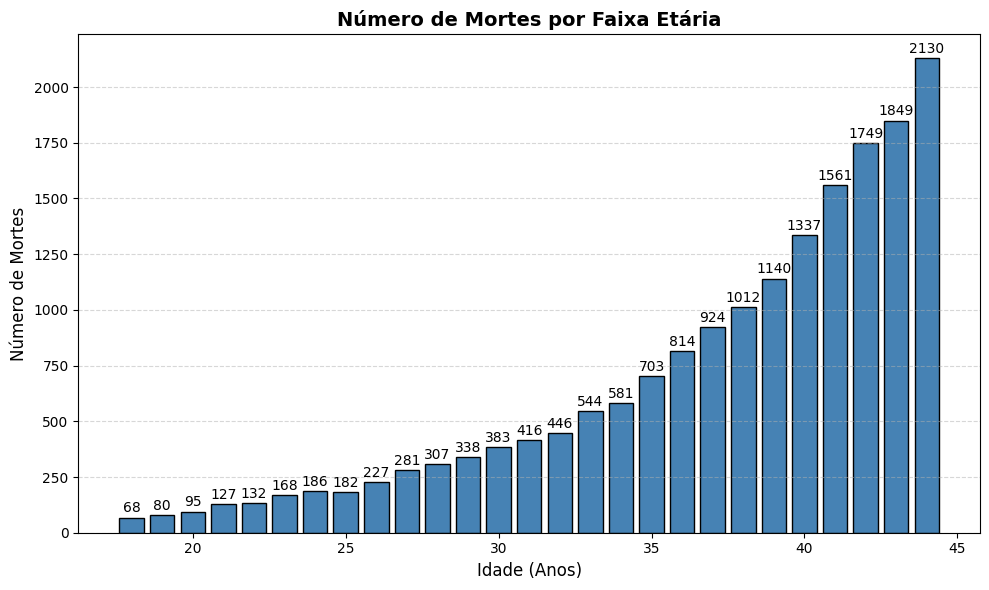

In [199]:
plt.figure(figsize=(10, 6))

# 3. Criar o gráfico de barras
barras = plt.bar(dft['IDADE'], dft['CAUSABAS'], color='steelblue', edgecolor='black')

# 4. Adicionar títulos e rótulos nos eixos
plt.title('Número de Mortes por Faixa Etária', fontsize=14, fontweight='bold')
plt.xlabel('Idade (Anos)', fontsize=12)
plt.ylabel('Número de Mortes', fontsize=12)

# 5. Adicionar o valor exato no topo de cada barra
for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 10,  # Pequeno espaço acima da barra
        f'{int(altura)}',
        ha='center',
        va='bottom',
        fontsize=10
    )

# 6. Ajustar grade e exibir
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
fig.savefig("fig/grafico_barra.png", dpi=200, bbox_inches="tight")
plt.show()

In [196]:
dft_media = dft['CAUSABAS'].mean()
dft_desvio = dft['CAUSABAS'].std()
porcentagemDesvio = dft_desvio/dft_media * 100

print(dft_media)
print(dft_desvio)
print(porcentagemDesvio)




658.5185185185185
604.6469007973783
91.81927064977062


In [143]:
#prob_menor_30 = norm.cdf(18, loc=dft_media, scale=dft_desvio)
#print(f"Chance de ter até 30 mortes: {prob_menor_30:.2%}")



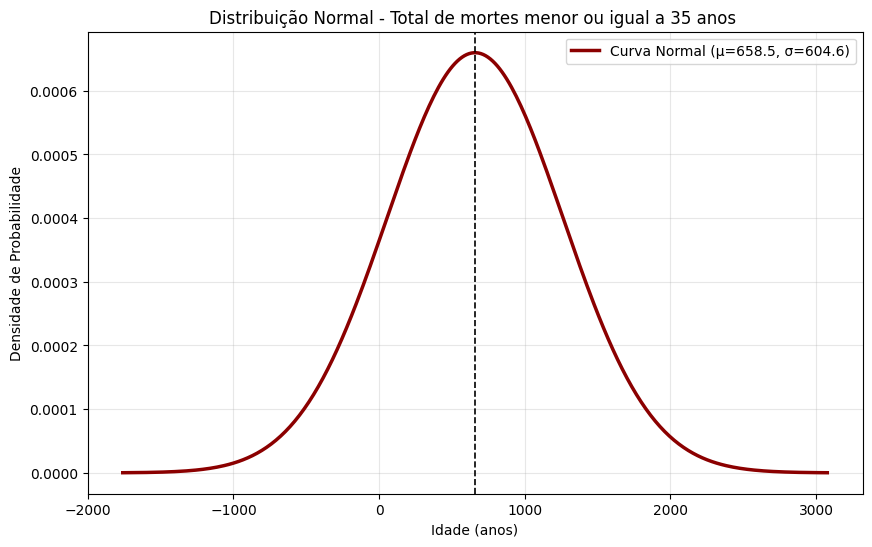

In [192]:
plt.figure(figsize=(10, 6))
dados = dft['CAUSABAS']

# 3. Calcular e desenhar uma curva para cada causa
media = dft_media
desvio = dft_desvio
x = np.linspace(media - 4 * desvio, media + 4 * desvio, 300)
y = norm.pdf(x, loc=media, scale=desvio)

plt.plot(
    x,
    y,
    color='darkred',
    linewidth=2.5,
    label=f'Curva Normal (μ={media:.1f}, σ={desvio:.1f})',
)

plt.axvline(media, color='black', linestyle='--', linewidth=1.2)

plt.title('Distribuição Normal - Total de mortes menor ou igual a 35 anos ')
plt.xlabel('Idade (anos)')
plt.ylabel('Densidade de Probabilidade')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [193]:
#INTERVALO DE CONFIANÇA
erro_padrao = stats.sem(dados)  
confianca = 0.95


ic_normal = stats.norm.interval(confianca, loc=media, scale=erro_padrao)

ic_t = stats.t.interval(
    confianca, df=len(dados) - 1, loc=media, scale=erro_padrao
)

print(f'Média amostral: {media:.2f}')
print(f'IC 95% (Normal): {ic_normal[0]:.2f} a {ic_normal[1]:.2f}')


Média amostral: 658.52
IC 95% (Normal): 430.45 a 886.59


In [194]:
#P-VALOR (Teste de Hipotese)
valor_referencia = 886  # Hipótese nula (H0): média = 40

# Teste t de uma amostra (mais usado na prática)
estatistica_t, p_valor = stats.ttest_1samp(dados, popmean=valor_referencia, alternative='two-sided')

print(f'Estatística t: {estatistica_t:.4f}')
print(f'p-valor: {p_valor:.4f}')

# Interpretação automática (nível de significância alfa = 0.05)
if p_valor < 0.05:
  print(f'Resultado significativo: rejeitamos H0 (a média é diferente de {valor_referencia}.')
else:
  print(
      f'Não Rejeita H0 a média não difere de {valor_referencia}'
  )


Estatística t: -1.9549
p-valor: 0.0614
Não Rejeita H0 a média não difere de 886
